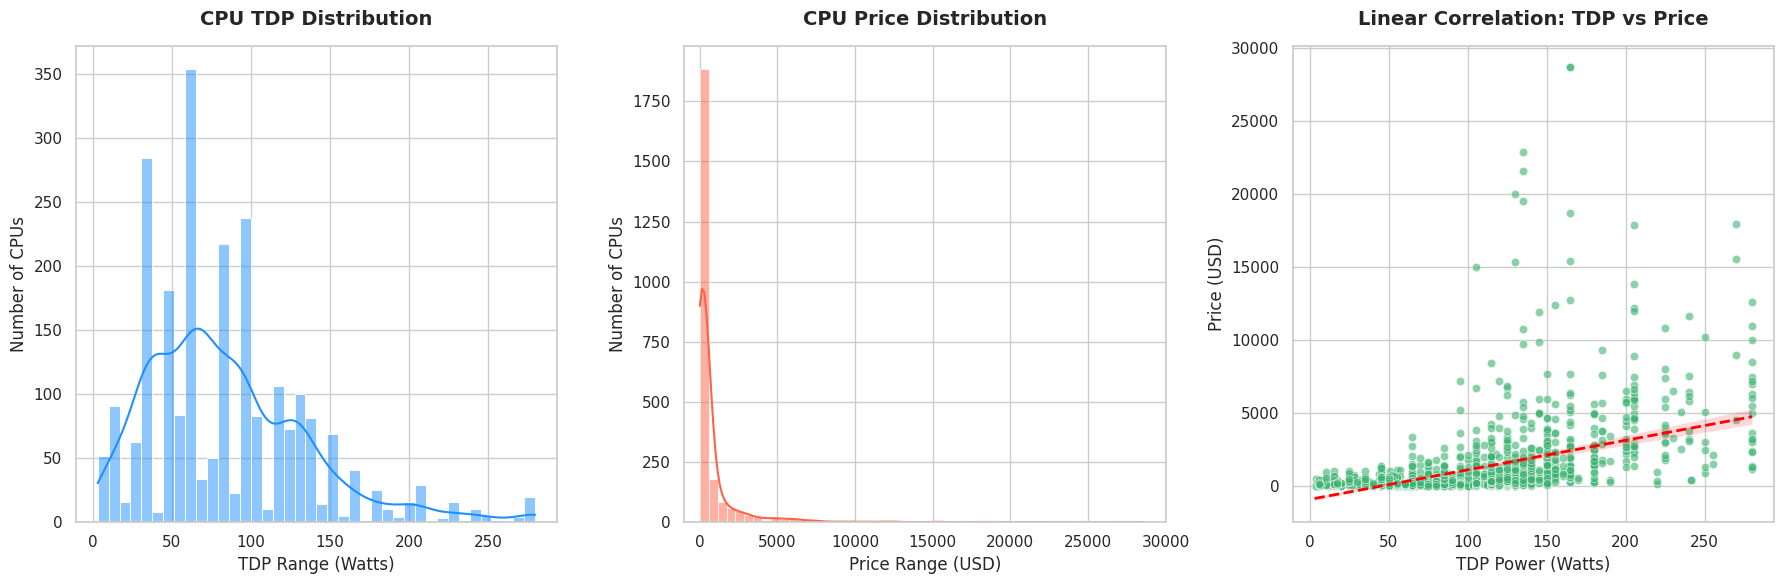

In [ ]:
# ==============================================================================
# ĐIỀU CHỈNH BIẾN ĐẦU VÀO X (speed_ghz) VÀ BIẾN MỤC TIÊU Y (rank)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Nạp và làm sạch dữ liệu với biến mới
dataset_path = 'Final_CPU_Data_Cleaned.csv'
df = pd.read_csv(dataset_path)

# Lọc bỏ các dòng thiếu speed_ghz hoặc rank
df_clean = df.dropna(subset=['speed_ghz', 'rank']).copy()
df_clean = df_clean[(df_clean['speed_ghz'] > 0) & (df_clean['rank'] > 0)]

# Gán biến X và y theo đúng thống nhất của nhóm
X_raw = df_clean[['speed_ghz']].values
y_raw = df_clean[['rank']].values

print(f"Số lượng quan sát hợp lệ cho mô hình Hiệu năng: {len(df_clean)} dòng.")

# 2. Trực quan hóa tương quan mới: Tốc độ xung nhịp vs Thứ hạng/Hiệu năng
plt.figure(figsize=(8, 5))
sns.regplot(x=df_clean['speed_ghz'], y=df_clean['rank'], 
            scatter_kws={'alpha':0.5, 'color':'purple', 'edgecolor': 'w', 'linewidths': 0.5}, 
            line_kws={'color':'red', 'linewidth': 2, 'linestyle': '--'})
plt.title('Linear Correlation: CPU Clock Speed vs Rank/Benchmark', fontsize=12, fontweight='bold')
plt.xlabel('Clock Speed (GHz)', fontsize=11)
plt.ylabel('CPU Rank / Benchmark Score', fontsize=11)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. HUẤN LUYỆN MÔ HÌNH VỚI DỮ LIỆU MỚI (Gradient Descent & Normal Equation)
# ==============================================================================
# Chuẩn hóa dữ liệu X
X_mean = np.mean(X_raw)
X_std = np.std(X_raw)
X_scaled = (X_raw - X_mean) / X_std

m = len(X_raw)
X_b = np.c_[np.ones((m, 1)), X_scaled]
y_vec = y_raw.reshape(-1, 1)

def compute_cost(X, y, theta):
    predictions = X.dot(theta)
    errors = predictions - y
    return (1 / (2 * len(y))) * np.sum(np.square(errors))

def gradient_descent(X, y, theta, learning_rate, iterations):
    cost_history = np.zeros(iterations)
    for i in range(iterations):
        predictions = X.dot(theta)
        errors = predictions - y
        gradients = (1 / len(y)) * X.T.dot(errors)
        theta = theta - learning_rate * gradients
        cost_history[i] = compute_cost(X, y, theta)
    return theta, cost_history

# Chạy Gradient Descent
theta_initial = np.random.randn(2, 1)
alpha = 0.1
iterations = 500
theta_gd, cost_history = gradient_descent(X_b, y_vec, theta_initial, alpha, iterations)

print("\n--- KẾT QUẢ HUẤN LUYỆN MỚI (Hiệu năng CPU) ---")
print(f"Hệ số chặn (theta_0): {theta_gd[0][0]:.4f}")
print(f"Hệ số góc (theta_1):  {theta_gd[1][0]:.4f}")
print(f"Chi phí MSE cuối cùng: {cost_history[-1]:.4f}")

In [7]:
# ==============================================================================
# BƯỚC 2: CƠ SỞ TOÁN HỌC VÀ GRADIENT DESCENT (Nhiệm vụ 3, 4, 5 - Xuân Hạ)
# ==============================================================================
import numpy as np

# 1. Chuẩn bị dữ liệu và Chuẩn hóa (Feature Scaling - Z-score Standardization)
# Giúp Gradient Descent hội tụ nhanh và không bị tràn số (overflow)
X_mean = np.mean(X_raw)
X_std = np.std(X_raw)
X_scaled = (X_raw - X_mean) / X_std

# Thêm cột x0 = 1 vào ma trận X để tính hệ số chặn (bias/intercept theta_0)
m = len(X_raw)
X_b = np.c_[np.ones((m, 1)), X_scaled]  # Kích thước: (2425, 2)
y_vec = y_raw.reshape(-1, 1)            # Kích thước: (2425, 1)

# ==============================================================================
# NHIỆM VỤ 3: HÀM CHI PHÍ (COST FUNCTION J)
# Công thức: J(theta) = (1 / 2m) * sum( (X * theta - y)^2 )
# ==============================================================================
def compute_cost(X, y, theta):
    m = len(y)
    predictions = X.dot(theta)
    errors = predictions - y
    cost = (1 / (2 * m)) * np.sum(np.square(errors))
    return cost

# ==============================================================================
# NHIỆM VỤ 4: THUẬT TOÁN GRADIENT DESCENT (TỪ ĐẦU)
# Công thức cập nhật: theta = theta - alpha * (1/m) * X^T * (X * theta - y)
# ==============================================================================
def gradient_descent(X, y, theta, learning_rate, iterations):
    m = len(y)
    cost_history = np.zeros(iterations)
    theta_history = np.zeros((iterations, 2))
    
    for i in range(iterations):
        predictions = X.dot(theta)
        errors = predictions - y
        
        # Tính vector đạo hàm (Gradient vector)
        gradients = (1 / m) * X.T.dot(errors)
        
        # Cập nhật tham số theta
        theta = theta - learning_rate * gradients
        
        # Lưu lại lịch sử để Đạt Sang vẽ biểu đồ hội tụ (Nhiệm vụ 6,7)
        theta_history[i, :] = theta.T
        cost_history[i] = compute_cost(X, y, theta)
        
    return theta, cost_history, theta_history

# Khởi tạo tham số và chạy Gradient Descent
theta_initial = np.random.randn(2, 1) # Khởi tạo theta ngẫu nhiên
alpha = 0.1                           # Learning rate
iterations = 500                      # Số vòng lặp

print("Đang huấn luyện mô hình bằng Gradient Descent...")
theta_gd, cost_history, theta_history = gradient_descent(X_b, y_vec, theta_initial, alpha, iterations)

print("\n--- KẾT QUẢ TỪ GRADIENT DESCENT (Nhiệm vụ 4) ---")
print(f"Hệ số chặn (theta_0): {theta_gd[0][0]:.4f}")
print(f"Hệ số góc (theta_1):  {theta_gd[1][0]:.4f}")
print(f"Chi phí MSE cuối cùng: {cost_history[-1]:.4f}")

# ==============================================================================
# NHIỆM VỤ 5: NGHIỆM GIẢI TÍCH (CLOSED-FORM SOLUTION / NORMAL EQUATION)
# Công thức: theta = (X^T * X)^-1 * X^T * y
# ==============================================================================
def normal_equation(X, y):
    # Tính toán ma trận: nghịch đảo của (X_transpose nhân X) nhân X_transpose nhân y
    theta_best = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)
    return theta_best

theta_analytic = normal_equation(X_b, y_vec)

print("\n--- KẾT QUẢ TỪ NGHIỆM GIẢI TÍCH (Nhiệm vụ 5) ---")
print(f"Hệ số chặn (theta_0): {theta_analytic[0][0]:.4f}")
print(f"Hệ số góc (theta_1):  {theta_analytic[1][0]:.4f}")

# Đối chiếu kết quả
sai_so = np.sum(np.abs(theta_gd - theta_analytic))
print(f"\n=> Độ chênh lệch giữa 2 phương pháp: {sai_so:.8f} (Càng sát 0 càng chính xác)")

Đang huấn luyện mô hình bằng Gradient Descent...

--- KẾT QUẢ TỪ GRADIENT DESCENT (Nhiệm vụ 4) ---
Hệ số chặn (theta_0): 806.3621
Hệ số góc (theta_1):  1045.6391
Chi phí MSE cuối cùng: 1607977.2704

--- KẾT QUẢ TỪ NGHIỆM GIẢI TÍCH (Nhiệm vụ 5) ---
Hệ số chặn (theta_0): 806.3621
Hệ số góc (theta_1):  1045.6391

=> Độ chênh lệch giữa 2 phương pháp: 0.00000000 (Càng sát 0 càng chính xác)
